# depth of observations

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import pearsonr

import warnings
warnings.filterwarnings("ignore")

IOPATH = '/ocean/rbeutel/MOAD/analysis-becca/Synthesis/data/CCS_obs.csv'

In [3]:
obs = pd.read_csv(IOPATH)

# reduce potential bias caused by sampling programs going out in different months
# summer only (april-sep inclusive) based on PreliminaryCurrentAnalysis.ipynb
obs = obs[(obs.month>=4)&(obs.month<=9)]

In [25]:
def plot_depth(var_string,obs, subplot_pos,*,
                        binyears=True, min_obs_per_year=3, yax=False, xax=False):
    
    # === plotting ===
    ax_tr = ax[subplot_pos]
    ax_tr.set_yticks([0,100,200,300,400,500])
    ax_tr.set_xticks([-1000,-500,0,500,1000,1500,2000,2500])

    if yax == True:
        ax_tr.set_ylabel('Depth (m)')
        ax_tr.set_yticklabels(['0','','200','','400',''])
    else: 
        ax_tr.set_yticklabels([])

    if xax == True:
        ax_tr.set_xlabel('Distance Along Line (km)')
        ax_tr.set_xticklabels(['-1000','','0','','1000','','2000',''])
    else: 
        ax_tr.set_xticklabels([])
    #==------------------
    
    ax_tr.set_title(var_string)
    obs_used = obs[~np.isnan(obs[var_string])]

    dist = np.asarray(obs_used['dist'])
    dmin, dmax =  -1415, 2950
    if binyears == True:
        n_bins=9
        # bin edges/centers/widths
        edges   = np.linspace(dmin, dmax, n_bins+1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        colour='blue'
    else:
        bin_size = 150
        edges = np.arange(dmin,dmax+150,150)
        centers = 0.5 * (edges[:-1] + edges[1:])
        colour='magenta'
        n_bins=len(centers)

    depths = np.full(n_bins, np.nan) 
    q25 = np.full(n_bins, np.nan)
    q75 = np.full(n_bins, np.nan)

    # year_set   = np.full(n_bins, np.nan)   # NaN => excluded

    years_all = np.asarray(obs_used['year'])
    y_all     = np.asarray(obs_used['depth (m)'])

    for i in range(n_bins):
        lo, hi = edges[i], edges[i+1]
        msk = (dist >= lo) & (dist < hi) & np.isfinite(years_all) & np.isfinite(y_all)
        if not np.any(msk):
            continue

        depths[i] = np.mean(y_all[msk].astype(float))
        q25[i] = np.percentile(y_all[msk].astype(float),25)
        q75[i] = np.percentile(y_all[msk].astype(float),75)
        
    # points + 95% CI for valid bins only
    m_ok = np.isfinite(depths) & np.isfinite(q25) & np.isfinite(q75)
    if np.any(m_ok):
        ax_tr.plot(centers[m_ok], depths[m_ok],colour)
        ax_tr.fill_between(centers[m_ok], q25[m_ok],q75[m_ok], color=colour,alpha=0.3)
    ax_tr.set_ylim([500,0])
    ax_tr.set_xlim([dmin,dmax])

    # add lines for JdF, Cape Mendocino, and Point Conception
    ax_tr.plot([805,805],[-1000,1000],'k--',alpha=0.5) # Cape Mendocino
    ax_tr.plot([1654,1654],[-1000,1000],'k--',alpha=0.5) # Point Conception
    ax_tr.text(0.63,0.02,'CM',ha='right',va='bottom',transform=ax_tr.transAxes,fontsize=10)
    ax_tr.text(0.81,0.02,'PC',ha='right',va='bottom',transform=ax_tr.transAxes,fontsize=10)


    ax_tr.set_zorder(3)
    ax_tr.patch.set_alpha(0)
    # ax_tr.legend(loc='best')

    return depths


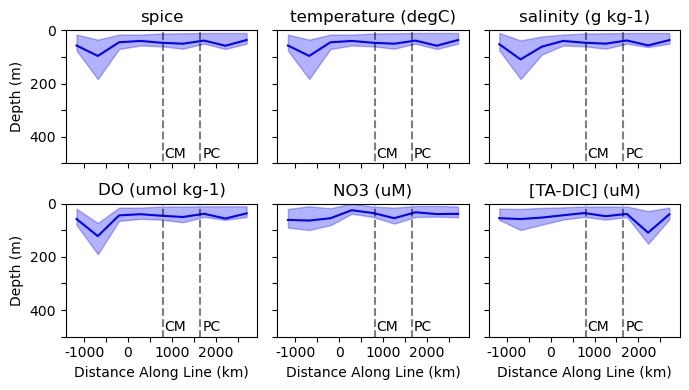

In [ ]:
fig, ax = plt.subplots(2,3, figsize=(7, 4))
Dspice = plot_depth('spice', obs_shelf, (0,0),yax=True)
Dtemp = plot_depth('temperature (degC)', obs_shelf, (0,1))
Dsalt = plot_depth('salinity (g kg-1)', obs_shelf, (0,2))
Ddo = plot_depth('DO (umol kg-1)', obs_shelf, (1,0),yax=True,xax=True)
Dno3 = plot_depth('NO3 (uM)', obs_shelf, (1,1),xax=True)
Dtadic = plot_depth('[TA-DIC] (uM)', obs_shelf, (1,2),xax=True)

# Dspice_path = plot_depth('spice', obs_shelf, (0,0),yax=True,binyears=False)
# Dtemp_path = plot_depth('temperature (degC)', obs_shelf, (0,1),binyears=False)
# Dsalt_path = plot_depth('salinity (g kg-1)', obs_shelf, (0,2),binyears=False)
# Ddo_path = plot_depth('DO (umol kg-1)', obs_shelf, (1,0),yax=True,xax=True,binyears=False)
# Dno3_path = plot_depth('NO3 (uM)', obs_shelf, (1,1),xax=True,binyears=False)
# Dtadic_path = plot_depth('[TA-DIC] (uM)', obs_shelf, (1,2),xax=True,binyears=False)

plt.tight_layout()

# plt.savefig('./output/shelfobsdepth.png')

In [27]:
# print difference in depth between the first and last bin
print(f'spice depth change = {Dspice[0]-Dspice[-1]}')
print(f'temp depth change = {Dtemp[0]-Dtemp[-1]}')
print(f'salt depth change = {Dsalt[0]-Dsalt[-1]}')
print(f'do depth change = {Ddo[0]-Ddo[-1]}')
print(f'no3 depth change = {Dno3[0]-Dno3[-1]}')
print(f'tadic depth change = {Dtadic[0]-Dtadic[-1]}')

spice depth change = 20.690590378366515
temp depth change = 20.690590378366515
salt depth change = 15.675959150681223
do depth change = 21.192537662945902
no3 depth change = 22.595772099144547
tadic depth change = 14.656799690042618


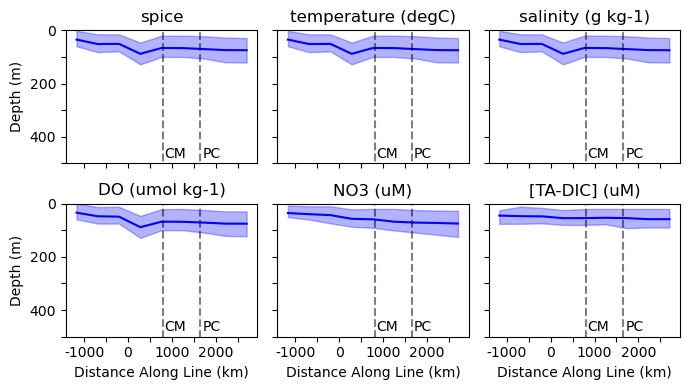

In [28]:
fig, ax = plt.subplots(2,3, figsize=(7, 4))
Dspice = plot_depth('spice', obs_cc, (0,0),yax=True)
Dtemp = plot_depth('temperature (degC)', obs_cc, (0,1))
Dsalt = plot_depth('salinity (g kg-1)', obs_cc, (0,2))
Ddo = plot_depth('DO (umol kg-1)', obs_cc, (1,0),yax=True,xax=True)
Dno3 = plot_depth('NO3 (uM)', obs_cc, (1,1),xax=True)
Dtadic = plot_depth('[TA-DIC] (uM)', obs_cc, (1,2),xax=True)

plt.tight_layout()

plt.savefig('./output/CCobsdepth.png')

In [29]:
# print difference in depth between the first and last bin
print(f'spice depth change = {Dspice[0]-Dspice[-1]}')
print(f'temp depth change = {Dtemp[0]-Dtemp[-1]}')
print(f'salt depth change = {Dsalt[0]-Dsalt[-1]}')
print(f'do depth change = {Ddo[0]-Ddo[-1]}')
print(f'no3 depth change = {Dno3[0]-Dno3[-1]}')
print(f'tadic depth change = {Dtadic[0]-Dtadic[-1]}')

spice depth change = -39.930299361871334
temp depth change = -39.930299361871334
salt depth change = -39.930299361871334
do depth change = -41.381661299783424
no3 depth change = -39.37328470316337
tadic depth change = -13.438979963570134


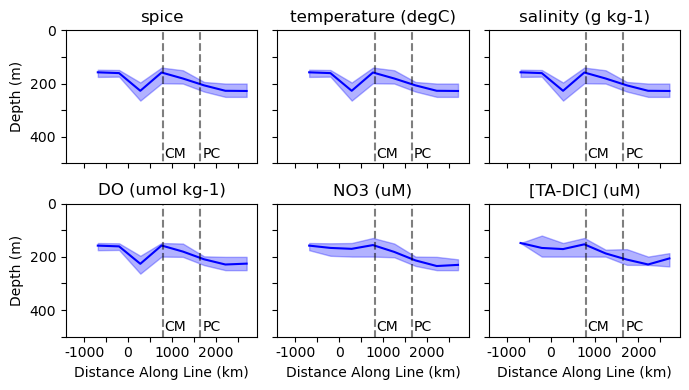

In [30]:
fig, ax = plt.subplots(2,3, figsize=(7, 4))
Dspice = plot_depth('spice', obs_cuc, (0,0),yax=True)
Dtemp = plot_depth('temperature (degC)', obs_cuc, (0,1))
Dsalt = plot_depth('salinity (g kg-1)', obs_cuc, (0,2))
Ddo = plot_depth('DO (umol kg-1)', obs_cuc, (1,0),yax=True,xax=True)
Dno3 = plot_depth('NO3 (uM)', obs_cuc, (1,1),xax=True)
Dtadic = plot_depth('[TA-DIC] (uM)', obs_cuc, (1,2),xax=True)

plt.tight_layout()

plt.savefig('./output/CUCobsdepth.png')

In [31]:
# print difference in depth between the first and last bin
print(f'spice depth change = {Dspice[1]-Dspice[-1]}')
print(f'temp depth change = {Dtemp[1]-Dtemp[-1]}')
print(f'salt depth change = {Dsalt[1]-Dsalt[-1]}')
print(f'do depth change = {Ddo[1]-Ddo[-1]}')
print(f'no3 depth change = {Dno3[1]-Dno3[-1]}')
print(f'tadic depth change = {Dtadic[1]-Dtadic[-1]}')

spice depth change = -70.06144159791575
temp depth change = -70.06144159791575
salt depth change = -70.06144159791575
do depth change = -67.69727434241886
no3 depth change = -72.38689809630458
tadic depth change = -57.85714285714286
